# 05 What-if rescheduling (December test set)

**Rule.** A flight whose predicted delay risk is >= 0.5 is offered a move of -2, -1, +1 or +2 hours on the same day.
It takes the move with the lowest predicted risk if risk drops by at least 0.05 and the target hour still has room.

**Assumptions** (all simplifications):
* the model's risk for the new slot is what the flight would face there; the model is associational, so this is a
  what-if estimate, not a causal effect
* only hour-dependent features change (departure/arrival time, hour congestion, origin-hour history); aircraft
  rotation, crew, gates and passengers are ignored
* at most 3 flights can be moved into one origin-hour slot per day
* departures stay between 05:00 and 23:59, and only move into hours the airport already operates that day

Model: logistic regression (best on validation) with rolling Platt calibration, so the risk levels match December.

In [1]:
import json

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

In [2]:
from pathlib import Path

ROOT = Path("..").resolve()
RAW_CSV = ROOT / "data_raw" / "flights.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
for d in (PROCESSED_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

RISK_THRESHOLD = 0.5
MIN_GAIN = 0.05
SLOT_CAPACITY = 3
SHIFTS = (-2, -1, 1, 2)
FIRST_HOUR, LAST_HOUR = 5, 23

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, LIGHT_GREY = "#8c8b86", "#c9c8c2"
TEXT, TEXT_2 = "#0b0b0b", "#52514e"
MODEL_COLORS = {"Prior rate": LIGHT_GREY, "Route history": GREY, "LR": BLUE, "XGBoost": ORANGE}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelcolor": TEXT_2, "axes.edgecolor": LIGHT_GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "lines.linewidth": 2, "legend.frameon": False, "text.color": TEXT,
})

In [4]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def cyclic(x, period):
    angle = 2 * np.pi * x / period
    return np.sin(angle), np.cos(angle)


class Platt:
    def fit(self, p, y):
        self.model = LogisticRegression(C=1e6).fit(logit(p)[:, None], y)
        return self

    def predict(self, p):
        return self.model.predict_proba(logit(p)[:, None])[:, 1]

In [5]:
feats = pd.read_pickle(PROCESSED_DIR / "features.pkl")
test = feats[(feats["split"] == "test") & ~feats["no_arrival"]].reset_index(drop=True)
history = pd.concat([pd.read_pickle(PROCESSED_DIR / "predictions_val.pkl"),
                     pd.read_pickle(PROCESSED_DIR / "predictions_test.pkl")], ignore_index=True)
with open(RESULTS_DIR / "selected_models.json") as f:
    window = json.load(f)["rolling_calibration"]["lr"]["window"]
model = joblib.load(MODEL_DIR / "lr.joblib")
print("rolling window:", window, "days")

rolling window: 28 days


## Daily calibrators and current risk

In [6]:
def daily_calibrators(history, dates, window):
    cals = {}
    for d in dates:
        past = history[(history["date"] < d) & (history["date"] >= d - pd.Timedelta(days=window))]
        cals[d] = Platt().fit(past["p_lr_raw"].to_numpy(), past["delayed"].to_numpy())
    return cals


def calibrated_risk(model, df, cals):
    raw = model.predict_proba(df)[:, 1]
    out = np.empty(len(df))
    for d, idx in df.groupby("date").indices.items():
        out[idx] = cals[d].predict(raw[idx])
    return out


cals = daily_calibrators(history, test["date"].unique(), window)
test["risk"] = calibrated_risk(model, test, cals)
test["risk"].describe().round(3)

count    27020.000
mean         0.298
std          0.128
min          0.033
25%          0.201
50%          0.282
75%          0.381
max          0.818
Name: risk, dtype: float64

## Candidate moves and greedy assignment

In [7]:
def build_candidates(flagged, feats):
    """One row per (flagged flight, shift) with the hour-dependent features recomputed."""
    slot_count = feats.groupby(["origin", "date", "hour"]).size()
    slot_hist = feats.groupby(["origin", "date", "hour"])["hist_rate_origin_hour"].first()

    rows = []
    for dh in SHIFTS:
        c = flagged.copy()
        c["shift"] = dh
        c["new_hour"] = c["hour"] + dh
        c = c[(c["new_hour"] >= FIRST_HOUR) & (c["new_hour"] <= LAST_HOUR)]
        key = pd.MultiIndex.from_arrays([c["origin"], c["date"], c["new_hour"]])
        # only move into hours where the airport already runs flights that day
        c["origin_hour_flights"] = slot_count.reindex(key).to_numpy() + 1
        c["hist_rate_origin_hour"] = slot_hist.reindex(key).to_numpy()
        c = c[c["origin_hour_flights"].notna()]

        dep_min = c["new_hour"] * 60 + c["minute"]
        arr_min = ((c["sched_arr_time"] // 100) * 60 + c["sched_arr_time"] % 100 + dh * 60) % 1440
        c["dep_sin"], c["dep_cos"] = cyclic(dep_min, 1440)
        c["arr_sin"], c["arr_cos"] = cyclic(arr_min, 1440)
        c["dep_hour"] = c["new_hour"]
        c["overnight"] = (arr_min < dep_min).astype(int)
        rows.append(c)
    return pd.concat(rows, ignore_index=True)


def assign_moves(flagged, cands):
    """Greedy: riskiest flights choose first; a slot closes after SLOT_CAPACITY arrivals."""
    used = {}
    moves = []
    by_flight = cands.sort_values("risk").groupby("id")
    for _, f in flagged.sort_values("risk", ascending=False).iterrows():
        if f["id"] not in by_flight.groups:
            continue
        for _, c in by_flight.get_group(f["id"]).iterrows():
            if f["risk"] - c["risk"] < MIN_GAIN:
                break
            slot = (c["origin"], c["date"], c["new_hour"])
            if used.get(slot, 0) < SLOT_CAPACITY:
                used[slot] = used.get(slot, 0) + 1
                moves.append({"id": f["id"], "origin": f["origin"], "hour": f["hour"],
                              "shift": c["shift"], "risk_before": f["risk"],
                              "risk_after": c["risk"], "delayed": f["delayed"]})
                break
    return pd.DataFrame(moves)


def run(threshold):
    flagged = test[test["risk"] >= threshold].copy()
    if flagged.empty:
        return flagged, pd.DataFrame()
    cands = build_candidates(flagged, feats)
    cands["risk"] = calibrated_risk(model, cands, cals)
    return flagged, assign_moves(flagged, cands)


def summarise(flagged, moves, threshold):
    moved_gain = (moves["risk_before"] - moves["risk_after"]).sum() if len(moves) else 0.0
    return {
        "risk_threshold": threshold,
        "test_flights": len(test),
        "flagged": len(flagged),
        "flagged_observed_delay_rate": float(flagged["delayed"].mean()) if len(flagged) else np.nan,
        "moved": len(moves),
        "mean_risk_before_moved": float(moves["risk_before"].mean()) if len(moves) else np.nan,
        "mean_risk_after_moved": float(moves["risk_after"].mean()) if len(moves) else np.nan,
        "expected_delays_flagged_before": float(flagged["risk"].sum()),
        "expected_delays_flagged_after": float(flagged["risk"].sum() - moved_gain),
        "moved_earlier": int((moves["shift"] < 0).sum()) if len(moves) else 0,
        "moved_later": int((moves["shift"] > 0).sum()) if len(moves) else 0,
    }

## Results, with sensitivity to the risk threshold

In [8]:
rows = []
for thr in (0.4, 0.5, 0.6):
    flagged, moves = run(thr)
    rows.append(summarise(flagged, moves, thr))
    if thr == RISK_THRESHOLD:
        main_moves = moves
summary = pd.DataFrame(rows)
summary.to_csv(RESULTS_DIR / "reschedule_summary.csv", index=False)
summary.T.round(3)

,0,1,2
risk_threshold,0.400,0.500,0.600
test_flights,27020.000,27020.000,27020.000
flagged,5750.000,1979.000,473.000
flagged_observed_delay_rate,0.474,0.520,0.556
moved,295.000,133.000,33.000
mean_risk_before_moved,0.504,0.571,0.657
mean_risk_after_moved,0.444,0.510,0.595
expected_delays_flagged_before,2796.907,1123.389,309.117
expected_delays_flagged_after,2779.062,1115.302,307.079
moved_earlier,239.000,98.000,21.000


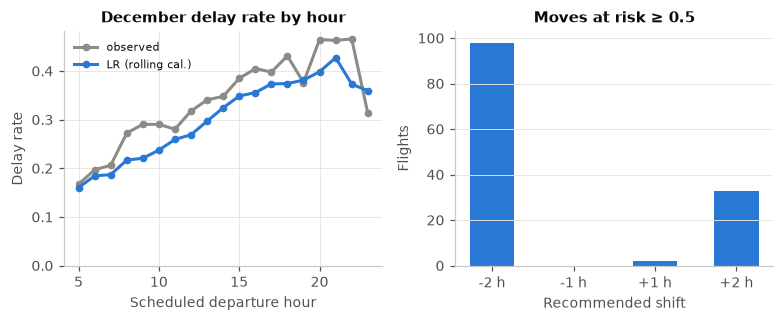

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
by_hour = test.groupby("hour").agg(observed=("delayed", "mean"), predicted=("risk", "mean"), n=("id", "size"))
by_hour = by_hour[by_hour["n"] >= 100]
axes[0].plot(by_hour.index, by_hour["observed"], marker="o", ms=4, color=GREY, label="observed")
axes[0].plot(by_hour.index, by_hour["predicted"], marker="o", ms=4, color=BLUE, label="LR (rolling cal.)")
axes[0].set(xlabel="Scheduled departure hour", ylabel="Delay rate", title="December delay rate by hour", ylim=(0, None))
axes[0].legend(loc="upper left", fontsize=7.5)

counts = main_moves["shift"].value_counts().reindex(SHIFTS, fill_value=0)
axes[1].bar([f"{s:+d} h" for s in SHIFTS], counts.values, color=BLUE, width=0.55)
axes[1].set(xlabel="Recommended shift", ylabel="Flights", title=f"Moves at risk ≥ {RISK_THRESHOLD}")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "reschedule.png")
plt.show()

The model's time-of-day profile follows the observed one, so "move earlier" is a plausible recommendation, but
within ±2 hours the predicted gain is small: most of the risk belongs to the day and the route, not the hour.

In [10]:
lines = [r"\begin{tabular}{lccc}", r"\toprule",
         r"Risk threshold & " + " & ".join(f"{t:.1f}" for t in summary["risk_threshold"]) + r" \\",
         r"\midrule"]
fmt = [("Flagged flights", "flagged", "{:.0f}"),
       ("Observed delay rate of flagged", "flagged_observed_delay_rate", "{:.3f}"),
       ("Flights moved", "moved", "{:.0f}"),
       ("Mean risk before (moved)", "mean_risk_before_moved", "{:.3f}"),
       ("Mean risk after (moved)", "mean_risk_after_moved", "{:.3f}"),
       ("Expected delays, flagged, before", "expected_delays_flagged_before", "{:.1f}"),
       ("Expected delays, flagged, after", "expected_delays_flagged_after", "{:.1f}")]
for label, col, f in fmt:
    lines.append(label + " & " + " & ".join(f.format(v) for v in summary[col]) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "reschedule.tex").write_text("\n".join(lines) + "\n")

main_row = summary.set_index("risk_threshold").loc[RISK_THRESHOLD]
macros = {
    "RSFlagged": f"{main_row['flagged']:,.0f}".replace(",", "{,}"),
    "RSMoved": f"{main_row['moved']:.0f}",
    "RSEarlier": f"{main_row['moved_earlier']:.0f}",
    "RSRiskBefore": f"{main_row['mean_risk_before_moved']:.3f}",
    "RSRiskAfter": f"{main_row['mean_risk_after_moved']:.3f}",
    "RSExpBefore": f"{main_row['expected_delays_flagged_before']:.0f}",
    "RSExpAfter": f"{main_row['expected_delays_flagged_after']:.0f}",
    "RSFlaggedRate": f"{main_row['flagged_observed_delay_rate']:.3f}",
}
with open(TABLE_DIR / "reschedule_numbers.tex", "w") as f:
    for k, v in macros.items():
        f.write(f"\\newcommand{{\\{k}}}{{{v}}}\n")
print("tables written")

tables written
